# Compton Scattering From Start To Finish

**Version**: 1

**Last modified**: 2026-10-12

**Compatible with opengate-gate-tree version:** 0.5.0

**Author**: Mateusz Jakub Bała

## About

A gamma that scatters in the detector and then interacts a second time leaves
two hits behind, and those two places are enough to measure the scattering:
where the gamma came from, where it scattered, and where it went next. This
notebook takes such tracks out of a "Hits" tree, rebuilds the directions
before and after the first interaction, measures the scattering angle, checks
it against the energy the scattering left behind, and estimates the
polarization each gamma had.

The part worth remembering is the first one: the momentum direction GATE
writes at a hit is the direction **after** the interaction, so the direction a
gamma arrived with is not in the file and has to be rebuilt from positions.

## What will you learn from this notebook

- how to put the hits of a track in order and take the first two of them
- how to rebuild the directions before and after a scattering from positions,
  and why `momDirX`, `momDirY` and `momDirZ` cannot stand in for the first one
- how to measure the scattering angle and read it in degrees
- how to check the angle against the energy the Compton formula predicts
- how to estimate the polarization of a gamma from the plane it scattered in,
  and how to compare the scattering planes of the two gammas of one decay

## Theory

A gamma of energy $E$ that scatters on an electron free and at rest, by the
angle $\theta$, leaves with the energy

$$
E' = \frac{E}{1 + \dfrac{E}{m_e c^2}\left(1 - \cos\theta\right)},
\qquad m_e c^2 = 510.999\ \text{keV},
$$

and the electron takes the difference, which is what a detector records as the
energy deposited at that hit:

$$
T = E - E'.
$$

For an annihilation gamma, $E = m_e c^2$, and the two read

$$
E' = \frac{E}{2 - \cos\theta},
\qquad
T = E\,\frac{1 - \cos\theta}{2 - \cos\theta},
$$

so the electron takes at most $T(\pi) = \tfrac{2}{3}E \approx 340.7$ keV — the
Compton edge.

The scattering angle is the angle between the direction before the scattering,
$\hat{k}_0$, and the direction after it, $\hat{k}$:

$$
\theta = \arccos\left(\hat{k}_0 \cdot \hat{k}\right),
\qquad \theta \in [0, \pi].
$$

Both directions are rebuilt from places: the source, the first hit $p_1$ and
the second hit $p_2$,

$$
\hat{k}_0 = \frac{p_1 - p_{\text{source}}}{\lVert p_1 - p_{\text{source}} \rVert},
\qquad
\hat{k} = \frac{p_2 - p_1}{\lVert p_2 - p_1 \rVert}.
$$

Compton scattering happens most readily perpendicular to the polarization of
the incoming gamma, so the estimate of that polarization is the normal of the
plane the gamma scattered in:

$$
\hat{\varepsilon} = \frac{\hat{k}_0 \times \hat{k}}{\lVert \hat{k}_0 \times \hat{k} \rVert}.
$$

## Tutorial

Every step below is a line of text, the code that does what the line says, and
a word about the answer where the answer needs one.

In [1]:
from tools import environment, paths, plotting

plotting.use_tutorial_style()
print(environment.describe())

opengate-gate-tree: 0.5.0
python: 3.14.5
run on: 2026-10-12


The header of this notebook states the version it was written for; the line
above states the version it just ran against. If they differ, the notebook may
still be right — but nobody has checked it against what is installed.

The file is a small GATE output carried in the repository: 500 hits of a
"Hits" tree with no system, described in
[`../data/README.md`](../data/README.md).

In [2]:
output = paths.output_dir("tutorial-14-compton-scattering")
example_input = paths.input_example("hits-a1-no-system.root")

In [3]:
import numpy as np

from opengate_gate_tree import (
    POSITION_COLUMNS,
    GateTree,
    angle_between,
    angle_between_planes,
    dot,
    momentum_direction_from_positions,
    norm,
    polarization_direction,
    rad_to_deg,
    read_tree,
)

### What The File Holds

The branches this notebook needs: the identifiers that name a track, the time
that puts its hits in order, the process and the energy of each hit, and three
positions and a direction.

In [4]:
# A tuple, so it is turned into a list: pandas reads a tuple as the name of one column.
POSITION = list(POSITION_COLUMNS)
SOURCE_COLUMNS = ["sourcePosX", "sourcePosY", "sourcePosZ"]
DIRECTION_COLUMNS = ["momDirX", "momDirY", "momDirZ"]
TRACK_KEY = ["runID", "eventID", "trackID"]

hits = read_tree(
    example_input,
    GateTree.HITS,
    [
        *TRACK_KEY,
        "parentID",
        "PDGEncoding",
        "time",
        "processName",
        "edep",
        "nCrystalRayleigh",
        "nPhantomRayleigh",
        *POSITION,
        *SOURCE_COLUMNS,
        *DIRECTION_COLUMNS,
    ],
).to_dataframe()
hits

,runID,eventID,trackID,parentID,PDGEncoding,time,processName,edep,nCrystalRayleigh,nPhantomRayleigh,posX,posY,posZ,sourcePosX,sourcePosY,sourcePosZ,momDirX,momDirY,momDirZ
0,0,0,2,0,22,0.000002,PhotoElectric,0.511000,0,0,-113.026367,-166.977676,19.670849,0.0,0.0,0.0,-0.557902,-0.824207,0.097096
1,0,0,1,0,22,0.000002,Compton,0.011562,0,0,111.593727,164.861191,-19.421516,0.0,0.0,0.0,0.528390,0.829366,-0.181536
2,0,0,1,0,22,0.000002,PhotoElectric,0.499438,0,0,113.613846,168.031998,-20.115559,0.0,0.0,0.0,0.528390,0.829366,-0.181536
3,0,1,2,0,22,0.000007,PhotoElectric,0.511000,0,0,-28.400776,168.522598,-126.842369,0.0,0.0,0.0,-0.133445,0.791828,-0.595987
4,0,1,1,0,22,0.000007,Compton,0.193163,0,0,27.451981,-162.892700,122.604897,0.0,0.0,0.0,0.663128,-0.686686,-0.297865
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,0,148,2,0,22,0.001535,PhotoElectric,0.511000,0,0,153.537720,-116.281227,80.393913,0.0,0.0,0.0,0.735664,-0.557152,0.385201
496,0,148,1,0,22,0.001535,PhotoElectric,0.511000,0,0,-150.718796,114.146324,-78.917892,0.0,0.0,0.0,-0.735664,0.557152,-0.385201
497,0,149,2,0,22,0.001545,Compton,0.149943,0,0,94.150391,-177.402954,26.348230,0.0,0.0,0.0,-0.007334,-0.560547,0.828090
498,0,149,2,0,22,0.001545,PhotoElectric,0.361057,0,0,94.139320,-178.248657,27.597578,0.0,0.0,0.0,-0.007334,-0.560547,0.828090


Every hit was left by a gamma (`PDGEncoding` 22), by one of two primary
tracks (`parentID` 0), and every gamma started at the origin:

In [5]:
{
    "PDGEncoding": hits["PDGEncoding"].unique().tolist(),
    "trackID": sorted(hits["trackID"].unique().tolist()),
    "parentID": hits["parentID"].unique().tolist(),
    "source positions": hits[SOURCE_COLUMNS].drop_duplicates().to_numpy().tolist(),
}

{'PDGEncoding': [22],
 'trackID': [1, 2],
 'parentID': [0],
 'source positions': [[0.0, 0.0, 0.0]]}

What energy did the gammas carry? A gamma absorbed whole deposits all of it,
so the sum of the energies along a track says it — `edep` is in MeV:

In [6]:
hits.groupby(TRACK_KEY)["edep"].sum().round(4).value_counts()

edep
0.511    300
Name: count, dtype: int64

Every one of the 300 tracks sums to 0.511 MeV: these are annihilation gammas
of 511 keV, two per event, sent from the origin, and each of them was absorbed
in the detector in the end. That is
the $E = m_e c^2$ of the theory above.

### The Hits Of A Track, In Order

A track is named by the run, the event and the track identifier together:
GATE numbers tracks within an event, so every event has a track 1. How many
hits does each track have?

In [7]:
hits.groupby(TRACK_KEY).size().value_counts().sort_index()

1    149
2    110
3     33
4      8
Name: count, dtype: int64

A hundred and fifty-one tracks have at least two hits, and those are the
ones a scattering can be measured on. The hits are put in order of time within
each track, and `cumcount()` numbers them from zero. The sort is stable, so
two hits with the same time keep the order the file gave them:

In [8]:
ordered = hits.sort_values([*TRACK_KEY, "time"], kind="stable")
ordered["hitOrder"] = ordered.groupby(TRACK_KEY).cumcount()

first = ordered[ordered["hitOrder"] == 0].set_index(TRACK_KEY)
second = ordered[ordered["hitOrder"] == 1].set_index(TRACK_KEY)

# Only the tracks with a second hit; both tables then hold the same rows, in the same order.
first = first.loc[second.index]
len(first), len(second)

(151, 151)

Indexing both tables by the track is what keeps them in step: `first.loc[...]`
puts the first hits in the order of the second ones, so row *i* of one and row
*i* of the other describe the same track. The arrays below are taken from them
by position, and that is only safe because of this line.

What happened at those hits?

In [9]:
{
    "first hit": first["processName"].value_counts().to_dict(),
    "second hit": second["processName"].value_counts().to_dict(),
}

{'first hit': {'Compton': 151},
 'second hit': {'PhotoElectric': 110, 'Compton': 41}}

Every first hit is a Compton scattering, as it has to be: a photoelectric
absorption ends the track, so there would be no second hit. The second hit is
mostly an absorption, and sometimes another scattering.

### The Directions Before And After

Three places per track, as `(N, 3)` arrays:

In [10]:
source = first[SOURCE_COLUMNS].to_numpy()
first_position = first[POSITION].to_numpy()
second_position = second[POSITION].to_numpy()

incoming = momentum_direction_from_positions(source, first_position)
outgoing = momentum_direction_from_positions(first_position, second_position)
incoming[:3], outgoing[:3]

(array([[ 0.55790192,  0.82420739, -0.09709597],
        [ 0.13344518, -0.79182795,  0.59598732],
        [-0.68332886,  0.17097983, -0.70980812]]),
 array([[ 0.5283891 ,  0.829367  , -0.18153603],
        [ 0.66312637, -0.68668855, -0.29786281],
        [-0.66698503,  0.37521571, -0.64369569]]))

Both are unit vectors, read in `float64` whatever the file holds. Now the
direction GATE wrote at the first hit, against each of them — in degrees:

In [11]:
written = first[DIRECTION_COLUMNS].to_numpy()

after = rad_to_deg(angle_between(written, outgoing))
before = rad_to_deg(angle_between(written, incoming))

print(f"written against the direction after:  largest difference {after.max():.4f} deg")
print(f"written against the direction before: median difference {np.median(before):.1f} deg")

written against the direction after:  largest difference 0.0073 deg
written against the direction before: median difference 56.4 deg


The written direction points at the next hit to within a hundredth of a
degree — the rest is the `float32` the file stores positions in. Against the
direction the gamma arrived with it differs by tens of degrees, which is the
scattering itself. So `momDirX`, `momDirY` and `momDirZ` are the direction
**after** the hit, and the direction before it has to be rebuilt from the
source and the hit, as above.

### The Scattering Angle

The angle between the direction before and the direction after, read in
degrees:

<Axes: title={'center': 'Scattering angle of the first interaction'}, xlabel='scattering angle [deg]', ylabel='counts / 10 deg'>

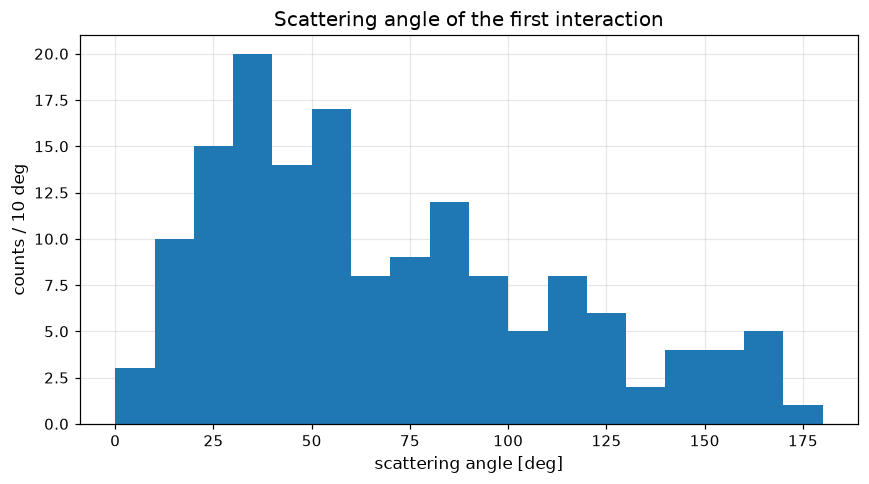

In [12]:
theta = angle_between(incoming, outgoing)
theta_deg = rad_to_deg(theta)

plotting.plot_hist_1d(
    theta_deg,
    xrange=(0, 180),
    xbins=18,
    xtitle="scattering angle [deg]",
    ytitle="counts / 10 deg",
    title="Scattering angle of the first interaction",
)

In [13]:
np.percentile(theta_deg, [0, 25, 50, 75, 100]).round(1)

array([  5.1,  35.9,  56.4,  96.3, 174.2])

The angles reach from 5° to 174°, and half of them lie below 56°. This is
not the Klein–Nishina distribution on its own: only gammas that interacted a
second time are in it, and whether a scattered gamma meets the detector again
depends on where it was sent. The histogram is the scattering as this detector
saw it.

### The Angle Against The Energy

The Compton formula ties the angle to the energy the electron took. With
$E = m_e c^2$, the energy the theory predicts for every measured angle, next to
the energy GATE recorded at the first hit:

<Axes: title={'center': 'What the scattering left behind'}, xlabel='scattering angle [deg]', ylabel='energy deposited [keV]'>

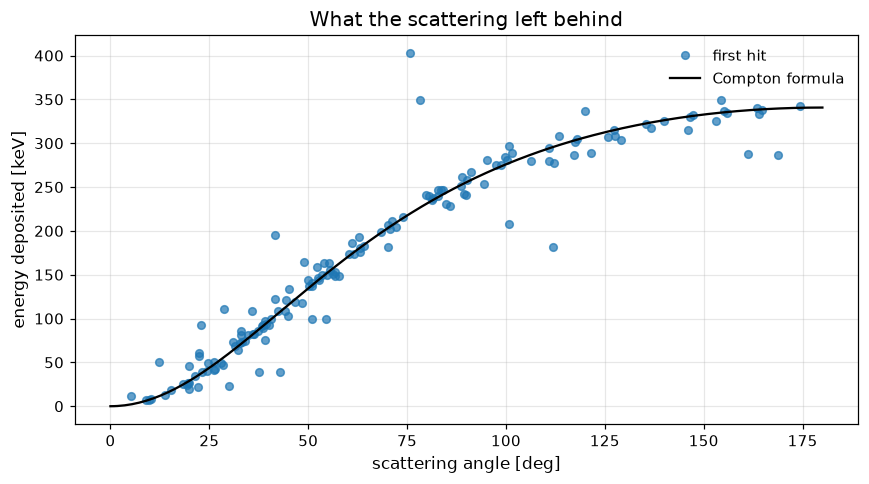

In [14]:
ELECTRON_MASS_KEV = 510.999
GAMMA_ENERGY_KEV = 511.0


def electron_energy(angle):
    """Energy an electron at rest takes from a gamma scattered by ``angle``, in keV."""
    ratio = GAMMA_ENERGY_KEV / ELECTRON_MASS_KEV
    return GAMMA_ENERGY_KEV - GAMMA_ENERGY_KEV / (1.0 + ratio * (1.0 - np.cos(angle)))


measured_kev = first["edep"].to_numpy() * 1000.0
curve = np.linspace(0.0, np.pi, 200)

plotting.plot_graphs(
    [
        plotting.GraphParams(theta_deg, measured_kev, label="first hit", alpha=0.7),
        plotting.GraphParams(
            rad_to_deg(curve),
            electron_energy(curve),
            label="Compton formula",
            marker="",
            linestyle="-",
            color="black",
        ),
    ],
    xtitle="scattering angle [deg]",
    ytitle="energy deposited [keV]",
    title="What the scattering left behind",
)

How close are they? The difference between what was recorded and what the
formula predicts, counted within a few widths:

In [15]:
difference = measured_kev - electron_energy(theta)

{
    f"within {width} keV": int(np.count_nonzero(np.abs(difference) < width))
    for width in (1, 5, 10, 20)
} | {"above the Compton edge": int(np.count_nonzero(measured_kev > 2 / 3 * GAMMA_ENERGY_KEV))}

{'within 1 keV': 24,
 'within 5 keV': 71,
 'within 10 keV': 97,
 'within 20 keV': 130,
 'above the Compton edge': 4}

Ninety-seven of the 151 scatterings lie within 10 keV of the curve, measured
only from where three hits sit — a good sign that the directions were rebuilt
correctly. The formula describes an electron free and at rest, and the
electrons of a crystal are neither, so a spread of a few keV around the curve
is expected. A handful of points lie tens of keV away, four of them beyond the
Compton edge, which no scattering on a free electron reaches.

A Rayleigh scattering would explain an angle that is off: it turns a gamma
without depositing anything, so no hit marks the turn. GATE counts those
scatterings on every hit, and in this file the count is zero throughout:

In [16]:
int((hits["nCrystalRayleigh"] + hits["nPhantomRayleigh"]).max())

0

So it is not a turn the hits missed, and the file does not say what it is.
Those are the tracks worth a look before an angle is trusted for one gamma
rather than for a distribution.

### The Polarization

The normal of the plane each gamma scattered in, from the same two
directions:

In [17]:
polarization = polarization_direction(incoming, outgoing)

{
    "largest |eps . k0|": float(np.abs(dot(polarization, incoming)).max()),
    "largest |eps . k|": float(np.abs(dot(polarization, outgoing)).max()),
    "lengths": (float(norm(polarization).min()), float(norm(polarization).max())),
}

{'largest |eps . k0|': 2.220446049250313e-16,
 'largest |eps . k|': 2.220446049250313e-16,
 'lengths': (0.9999999999999998, 1.0000000000000002)}

Perpendicular to both directions and of unit length, to the last bit of a
`float64`. It is an estimate per gamma, not a measurement: one scattering
fixes the plane, and the polarization is only distributed around its normal.
What the estimate is good for is a distribution over many gammas.

One such distribution is the angle between the scattering planes of the two
gammas of one decay. It needs events in which **both** gammas scattered and
interacted again:

In [18]:
per_track = first.reset_index()
gamma_1 = per_track[per_track["trackID"] == 1].set_index(["runID", "eventID"])
gamma_2 = per_track[per_track["trackID"] == 2].set_index(["runID", "eventID"])

both = gamma_1.index.intersection(gamma_2.index)
len(both)

35

The directions of those gammas, in the order of `both`. Each array was built
in the order of `first`, so it is indexed by the position each track has
there:

In [19]:
position_of = {track: row for row, track in enumerate(first.index)}
rows_1 = [position_of[(run, event, 1)] for run, event in both]
rows_2 = [position_of[(run, event, 2)] for run, event in both]

back_to_back = rad_to_deg(angle_between(incoming[rows_1], incoming[rows_2]))
print(f"opposite to within {180.0 - back_to_back.min():.3f} deg")

opposite to within 0.000 deg


The two gammas of every one of these decays left the origin in opposite
directions, to the precision printed, as annihilation gammas do. The angle between their scattering
planes — both pairs given in the same order, before and then after, since
reading one of them backwards would answer 180° minus the angle:

<Axes: title={'center': 'The two gammas of one decay'}, xlabel='angle between the scattering planes [deg]', ylabel='counts / 30 deg'>

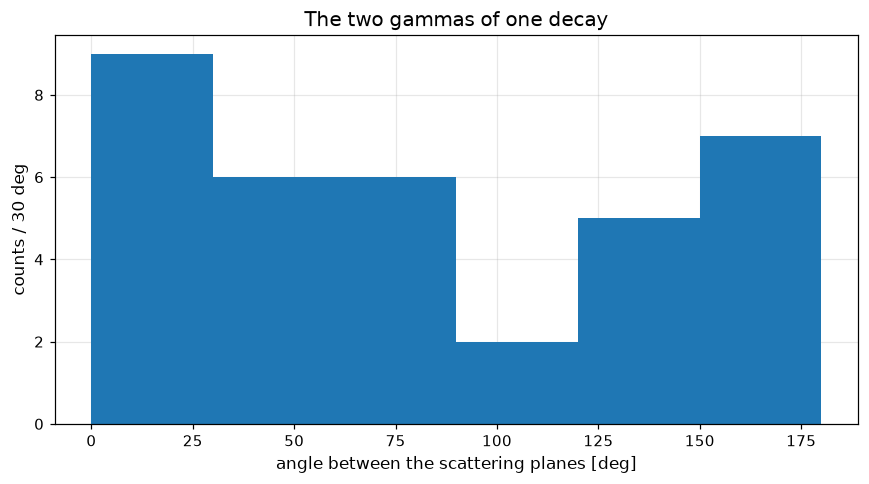

In [20]:
between_planes = rad_to_deg(
    angle_between_planes(incoming[rows_1], outgoing[rows_1], incoming[rows_2], outgoing[rows_2])
)

plotting.plot_hist_1d(
    between_planes,
    xrange=(0, 180),
    xbins=6,
    xtitle="angle between the scattering planes [deg]",
    ytitle="counts / 30 deg",
    title="The two gammas of one decay",
)

Thirty-five decays are far too few to show a shape, and the file does not say
whether the simulation gave the two gammas correlated polarizations at all. The
point is the recipe: with a simulation large enough, this is the histogram an
analysis of polarization correlations is built on.

## Summary

A scattering is measured from three places — the source, the first hit and the
second — because the direction GATE writes at a hit is the one the gamma left
with. `momentum_direction_from_positions` rebuilds both directions,
`angle_between` measures the scattering angle, which the Compton formula
confirms against the deposited energy, and `polarization_direction` with
`angle_between_planes` turns the scattering plane into an estimate of the
polarization.

## Bibliography

- [Vectors and angles](https://opengate-gate-tree.readthedocs.io/en/latest/guide/vectors.html)
  — the formulas for the angle, the plane normal, the rebuilt directions and
  the polarization, and why `momDir` is the direction after a hit
- [Event identifiers](https://opengate-gate-tree.readthedocs.io/en/latest/guide/events.html)
  — why a track is named by the run, the event and the track identifier
- [Units](https://opengate-gate-tree.readthedocs.io/en/latest/guide/units.html)
  — `edep` in MeV, angles in radians, and `rad_to_deg`
- [The "Hits" Tree](https://opengate-gate-tree.readthedocs.io/en/latest/guide/hits.html)
  — the branches this notebook reads
- A. H. Compton, *A Quantum Theory of the Scattering of X-rays by Light
  Elements*, Physical Review 21, 483 (1923) — the formula tying the angle to
  the energy

## Changelog

- v1: written.